# Smart microscopy with a spiral survey

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prakhar-Dutta/ASAP/blob/main/tutorials/dna-imaging/smart-scanning/notebooks/DNA_simulation_and_spiral_scanning.ipynb)

**Part 1 creates multi-molecule AFM frames for the smart-scanning experiment.** Choose molecular dynamics (MD) or the calibrated non-MD pathway, set the molecule count and physical frame dimensions, inspect initial and relaxed chains, compare with experimental relaxed-DNA Scan 55, and generate two sanity-check frames. Part 1 finishes by exporting a dataset with heights, masks, molecule identities, coordinates and seeds. **Part 2 loads the original manuscript diffusion or deterministic U-Net checkpoint, or optionally trains a new model, then predicts and assesses second-pass scan boxes on simulated data and real Scan 55 or your own SPM/NPY file.**

The experiment's defaults are **1–3 long DNA molecules per field**, a **640 × 640 nm square canvas**, a **1.25 nm composition grid** and a **2.5 nm model grid**. Each long molecule has a requested contour length of **768.4 nm**. The frame size and molecule count are configurable. A rectangular frame can have different width and height.

### Where the additional code and data live

| Path relative to this notebook | Contents |
|---|---|
| `../spiral_simulation_helpers.py` | All frame-composition, noise, plotting and dataset-export functions |
| `../../segmentation/dna_simulation_helpers.py` | Shared chain generation, OpenMM force field, calibrated AFM renderer and animation functions |
| `../setup_spiral.py` | Small-file download and dependency setup for Colab; creates the same sibling-folder layout as the repository |
| `../../common-assets/noise/md_single_blank_noise.npz` | Original processed blank used by the MD source scenes; paired JSON records provenance |
| `../../common-assets/noise/psd_noise_model.npz` | Optional ensemble spectral noise model |
| `../../common-assets/example-frames/relaxed_scan55.npz` | Whole native-grid, filtered Scan 55; paired JSON records pixel size and provenance |
| `../spiral_learning_helpers.py` | All network/dataset classes, DeepTrack lazy loading, losses, training, inference, ROI rules and real-data analysis |
| `../checkpoints/{diffusion,regression}/` | Original inference-only EMA weights, training curves and provenance |
| `../assets/reference-fields/` | Original 40 ROI-validation fields and one held-out simulated preview |
| `spiral_dataset_md/` or `spiral_dataset_non_md/` | Your exported dataset, created only when export is enabled |

The notebook uses the same MD and non-MD molecule generators as the segmentation tutorial. Its frame helper combines independently generated molecules and adds one background per frame. Molecules retain their physical contour lengths when positioned or clipped by a frame edge.

### Running in Colab

Open the badge above. For MD, choose **Runtime → Change runtime type → GPU**, then run **cell 0** before importing numerical libraries. Cell 0 downloads the helper files and small assets without cloning the repository. CPU also works; the non-MD pathway is useful for a quick first run. Local users can install `requirements.txt` and, for MD, `openmm`.

### Cell execution order

| Goal | Run |
|---|---|
| Run on Colab | **0**, then the cells below |
| Inspect the whole workflow | **1.1 → 1.2 → 1.3 → 2 → 3 → 4 → 5 → 6** |
| Generate the two example frames | **1.1 → 1.2 → 1.3 → 6** |
| Export a dataset | **1.1 → 1.2 → 1.3 → 7**; enable `GENERATE_DATASET` in cell 7 |
| Use the provided models and plan scans | **8 → 9 → 10 → 11 → 12 → 13 → 14 → 15**; run **0** first on Colab |
| Train a new model | Export a dataset in **7**, then **8 → 15** with `TRAIN_NEW_MODEL = True` |
| Show only real Scan 55 | **1.1 → 1.2 → 5** (plus **0** on Colab) |

Re-run cell 1.2 after changing the pathway or frame settings. Cells 2–5 are visual checks; dataset export does not depend on running them.

## 0. Colab setup

Run this cell first in a fresh Colab Python 3.12 runtime. It downloads both helpers, the original diffusion and regression EMA checkpoints, training curves, the 40 original simulated ROI-validation fields, one held-out simulated preview, noise assets and real Scan 55. It creates the same directory layout as the repository without cloning it.

`INSTALL_MD` installs OpenMM for Part 1. `INSTALL_TOPOSTATS` installs the existing ASAP Python 3.12 contour profile for loading and filtering your own SPM files. The default Scan 55 is already filtered. For MD or live neural-network inference, select a GPU runtime. The supplied reference-prediction caches let the manuscript previews run quickly on CPU too. Caches are accepted only for matching original weights and observations; your own files use live inference.


In [1]:
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

INSTALL_MD = True
INSTALL_TOPOSTATS = True
REPOSITORY_REF = "main"
ON_COLAB = "google.colab" in sys.modules
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if ON_COLAB or ON_KAGGLE:
    PROJECT_ROOT = Path("/content/ASAP") if ON_COLAB else Path("/kaggle/working/ASAP")
    TUTORIAL_DIR = PROJECT_ROOT / "tutorials/dna-imaging/smart-scanning"
    NOTEBOOK_DIR = TUTORIAL_DIR / "notebooks"
    NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)
    setup_script = TUTORIAL_DIR / "setup_spiral.py"
    if not setup_script.exists():
        setup_url = (f"https://raw.githubusercontent.com/Prakhar-Dutta/ASAP/{REPOSITORY_REF}/"
                     "tutorials/dna-imaging/smart-scanning/setup_spiral.py")
        urllib.request.urlretrieve(setup_url, setup_script)
    command = [sys.executable, str(setup_script), "--root", str(PROJECT_ROOT),
               "--ref", REPOSITORY_REF, "--md" if INSTALL_MD else "--no-md"]
    if INSTALL_TOPOSTATS:
        command.append("--install-topostats")
    subprocess.run(command, check=True)
    os.chdir(NOTEBOOK_DIR)
else:
    NOTEBOOK_DIR = Path.cwd()
    if not (NOTEBOOK_DIR.parent / "spiral_simulation_helpers.py").is_file():
        candidate = NOTEBOOK_DIR / "tutorials/dna-imaging/smart-scanning/notebooks"
        if candidate.is_dir():
            NOTEBOOK_DIR = candidate
            os.chdir(NOTEBOOK_DIR)
    print("Local run: install ../requirements.txt, OpenMM for MD, and the TopoStats profile for SPM files.")

print("Working folder:", Path.cwd())

Local run: install ../requirements.txt, OpenMM for MD, and the TopoStats profile for SPM files.
Working folder: C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\ASAP\tutorials\dna-imaging\smart-scanning\notebooks


# Part 1. Generate multi-molecule DNA frames

## 1.1 Imports and MD/non-MD choice

`USE_MD = True` relaxes closed three-dimensional chains onto a substrate with OpenMM. `False` generates calibrated closed two-dimensional chains directly. Non-MD rings have exact requested projected contour lengths; MD contours fluctuate slightly after relaxation. The force-field and rendering functions are shared with the segmentation notebook.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path('..').resolve()))
import spiral_simulation_helpers as spiral

sim = spiral.sim
USE_MD = True

if USE_MD:
    import openmm
    print("MD pathway | OpenMM", openmm.__version__)
else:
    print("Non-MD pathway | OpenMM is not required")

MD pathway | OpenMM 8.6.1


## 1.2 Dataset, frame and molecule settings

**Counts:** `(1, 3)` is an inclusive integer range, so each frame contains 1, 2 or 3 molecules, with equal probability. `(2, 4)` samples 2, 3 or 4. A list such as `[2, 4]` samples only the listed counts; repeated entries act as weights. An integer fixes the count.

**Dimensions:** choose `FRAME_SHAPE = "square"` or `"rectangle"`. Squares use `FRAME_WIDTH_NM` for both sides; rectangles use both dimensions. Dimensions must be multiples of the model pixel size. The default fine image has 512 × 512 pixels and the model image has 256 × 256 pixels; both cover 640 × 640 nm.

**Other specifications:** a list samples discrete values; a tuple samples uniformly over a continuous range. The default long-DNA contour is `[768.4]` nm. Changing bond length or per-bond stiffness changes the bead count or shape, while the requested contour length remains the control in nm.

The original spiral experiment composited cached MD molecules. Here, fresh molecules are generated using the shared optimised recipes. The first molecule is kept complete; extra molecules may cross a frame edge if at least 30% of their mask remains visible, matching the original placement principle. Set `ALLOW_PARTIAL_MOLECULES = False` to keep every molecule complete. Molecules are separated by at least 10 nm. Impossible packing produces a clear error rather than silently returning fewer molecules.

In [3]:
# Dataset
OUT_DIR = Path("spiral_dataset_md" if USE_MD else "spiral_dataset_non_md")
N_DATASET_FRAMES = 1000
BASE_SEED = 2026

# Physical frame and molecule count
MOLECULES_PER_FRAME = (1, 3)       # inclusive; try (2, 4) to sample 2, 3 or 4
FRAME_SHAPE = "square"            # "square" or "rectangle"
FRAME_WIDTH_NM = 640.0
FRAME_HEIGHT_NM = 640.0           # used for rectangles; squares use width for both
FINE_NM_PER_PIXEL = 1.25
MODEL_NM_PER_PIXEL = 2.5

# Molecular geometry and image formation
CONTOUR_LENGTHS_NM = [768.4]
CHAIN_RESOLUTION_NM = 0.5
DNA_HEIGHTS_NM = (1.8, 2.8) if USE_MD else [2.736565473663223]
TIP_RADII_NM = (6.0, 8.0) if USE_MD else [8.662717273203071]
NOISE_RMS_NM = (0.05, 0.17)

# Shared optimised pathway settings; these are copied, so edits stay in this notebook.
SIMULATION_SETTINGS = spiral.pathway_defaults(USE_MD)
BOND_LENGTH = 4.5 if USE_MD else 7.362098159496696
PERSISTENCE_BONDS = 40.0 if USE_MD else 8.395369256503411
K_ANGLE = 15
BASE_Z = 55.0
MD_RECORDED_FRAMES = 350
STEPS_PER_FRAME = 300
ANGLE_STIFFNESS_MULT = 1.3329571644033593

# Fine-tuning: keep the first molecule complete and allow partial additional molecules.
ALLOW_PARTIAL_MOLECULES = True
MINIMUM_VISIBLE_FRACTION = 0.30
MOLECULE_SEPARATION_NM = 10.0
PLACEMENT_ATTEMPTS = 200
CHAIN_ATTEMPTS = 5

SIMULATION_SETTINGS.update(
    BOND_LENGTH=BOND_LENGTH, PERSISTENCE_BONDS=PERSISTENCE_BONDS, K_ANGLE=K_ANGLE,
    BASE_Z=BASE_Z, N_FRAMES=MD_RECORDED_FRAMES, STEPS_PER_FRAME=STEPS_PER_FRAME,
    ANGLE_STIFFNESS_MULT=ANGLE_STIFFNESS_MULT, CHAIN_RESOLUTION_NM=CHAIN_RESOLUTION_NM,
)
SIMULATION_SETTINGS["AFM_KW"]["chain_resolution_nm"] = CHAIN_RESOLUTION_NM
# Other renderer settings can be inspected/edited in SIMULATION_SETTINGS["AFM_KW"].

FRAME_CONFIG = spiral.frame_config(
    FRAME_SHAPE, FRAME_WIDTH_NM, FRAME_HEIGHT_NM, FINE_NM_PER_PIXEL, MODEL_NM_PER_PIXEL,
    MOLECULES_PER_FRAME, ALLOW_PARTIAL_MOLECULES, MINIMUM_VISIBLE_FRACTION,
    MOLECULE_SEPARATION_NM, PLACEMENT_ATTEMPTS, CHAIN_ATTEMPTS,
)
REAL_SCAN55_PATH = Path("../../common-assets/example-frames/relaxed_scan55.npz")
print(f"Frame: {FRAME_CONFIG['width_nm']:g} × {FRAME_CONFIG['height_nm']:g} nm | "
      f"fine grid {FRAME_CONFIG['nx']} × {FRAME_CONFIG['ny']} | "
      f"model grid {FRAME_CONFIG['model_nx']} × {FRAME_CONFIG['model_ny']}")
print("Molecule counts:", FRAME_CONFIG["count_values"], "| expected mean:", FRAME_CONFIG["mean_molecule_count"])

Frame: 640 × 640 nm | fine grid 512 × 512 | model grid 256 × 256
Molecule counts: [1, 2, 3] | expected mean: 2.0


## 1.3 Noise

This cell uses the same blank-scan and PSD noise controls as the segmentation notebook. The default selects the **original MD experiment's single-blank spectral noise** by setting `USE_BLANK_SPM_NOISE = False` and pointing `MODEL_PATH` to its processed blank asset. Random Fourier phases produce a fresh background with that blank's spatial correlations. Set `USE_BLANK_SPM_NOISE = True` to use the blank SPM texture instead, or supply another PSD model through `MODEL_PATH`.

`TARGET_NOISE_RMS_NM` controls the single-image noise scale; `NOISE_RMS_NM` from cell 1.2 controls the per-frame sampling range. Background is added once to the composed frame. The original processed blank has native pixels of 1.953125 nm.


In [4]:
TARGET_NOISE_RMS_NM = 0.10 if USE_MD else 0.16

# Blank SPM noise: the same controls as the segmentation notebook.
USE_BLANK_SPM_NOISE = False    # original spiral MD training used the single-blank spectrum
USE_PLANE_REMOVE = True
USE_LINE_FLATTEN = True
USE_BANDPASS_FILTER = True
BLANK_SPM_PATH = "../../common-assets/noise/20240411_blank_water.0_00000.spm"
NOISE_NATIVE_NM_PER_PIXEL = 1.953125

# PSD fallback; use psd_noise_model.npz here for the shared ensemble model.
USE_PSD_NOISE_FALLBACK = True
MODEL_PATH = "../../common-assets/noise/md_single_blank_noise.npz"
PSD_NOISE_METHOD = "mean_full2d"
PSD_NOISE_STD_SCALE = 2.0

noise_source, noise_asset, noise_diag = spiral.load_noise_asset_from_settings(globals())

Noise source: single_blank_psd | asset: ..\..\common-assets\noise\md_single_blank_noise.npz


## 2. Create and visualise the chains

This schematic displays the **rounded mean number of chains**, with a different colour for each chain. For `(2, 4)`, the mean is 3 and the plot shows three chains. The printed mean describes the configured distribution, not a random two-frame estimate. MD chains are shown before substrate relaxation; non-MD rings are already generated on the substrate.

The positions in this schematic separate the chains for inspection. Actual frame positions are sampled after chain generation and checked during frame composition. Chain geometry is not scaled to make it fit.

Expected mean: 2; chains displayed: 2


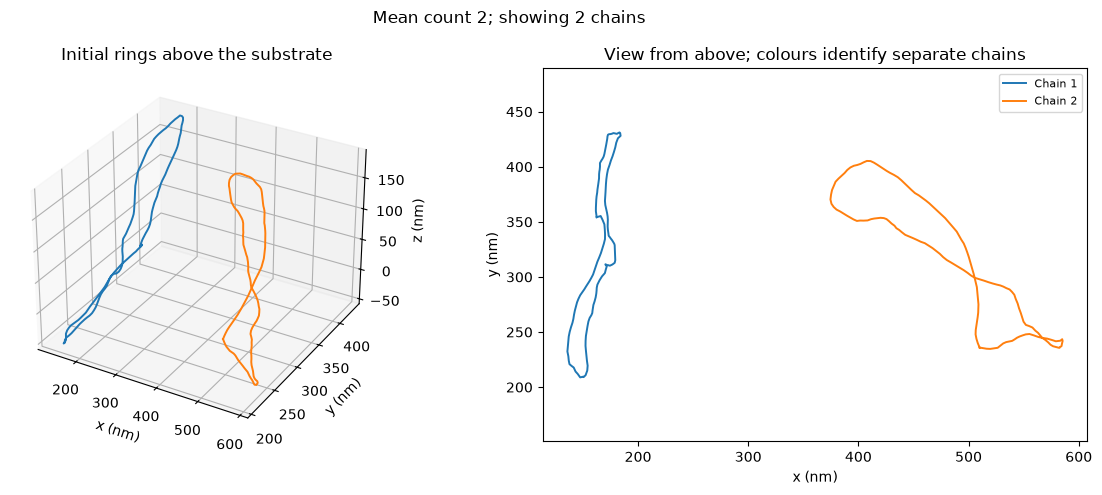

In [5]:
DEMO_SEED = 43
demo_chains = spiral.initial_chains(MOLECULES_PER_FRAME, DEMO_SEED, CONTOUR_LENGTHS_NM,
                                     SIMULATION_SETTINGS, FRAME_CONFIG)
print(f"Expected mean: {spiral.mean_molecule_count(MOLECULES_PER_FRAME):g}; "
      f"chains displayed: {len(demo_chains)}")
spiral.plot_initial_chains(demo_chains, MOLECULES_PER_FRAME, FRAME_CONFIG, USE_MD);

## 3. Check OpenMM for the MD pathway

When MD is selected, this optional check reports available OpenMM platforms and tests the installation. The shared `run_md_relaxation` function in `../../segmentation/dna_simulation_helpers.py` defines the relaxation forces and their annealing behaviour. Notebook variables expose bending stiffness, trajectory length and integration steps.

In [6]:
if USE_MD:
    sim.test_openmm_installation()
else:
    print("Non-MD pathway selected; continue to the relaxed-chain cell.")


OpenMM Version: 8.6.1
Git Revision: b399af4725573963b46d6c1083fdcf7a37615857



There are 3 Platforms available:

1 Reference 

- Successfully computed forces
2 CPU - Successfully computed forces
3 OpenCL 

- Successfully computed forces

Median difference in forces between platforms:

Reference vs. CPU: 6.29583e-06


Reference vs. OpenCL: 6.74321e-06
CPU vs. OpenCL: 7.86633e-07

All differences are within tolerance.


## 4. Relax one chain

Only **one chain** is used for this animation, irrespective of the configured molecules per frame. It uses the seed and contour of the first chain from the schematic. In MD mode, the animation shows relaxation onto the substrate; in non-MD mode, a static view shows the generated substrate configuration. The printed contour is the full chain length, even when a later frame contains only part of a molecule.

In [7]:
relax_seed = demo_chains[0]["seed"]
relax_contour_nm = demo_chains[0]["requested_contour_nm"]
with spiral.simulation_context(SIMULATION_SETTINGS):
    relaxed_chain = sim.generate_chain(relax_seed, relax_contour_nm, return_frames=True)
print(f"One chain, seed {relax_seed}: projected contour "
      f"{relaxed_chain['projected_contour_nm']:.1f} nm; 3-D contour {relaxed_chain['contour_3d_nm']:.1f} nm")
if USE_MD:
    animation_frames = relaxed_chain["frames"][::10] + [relaxed_chain["frames"][-1]]
    sim.show_md_animation(animation_frames)
else:
    sim.plot_relaxed_chain(relaxed_chain["coords"], title=f"Non-MD configuration, seed {relax_seed}")

  CUDA unavailable: There is no registered Platform called "CUDA"


Using OpenCL platform.


One chain, seed 1085174817: projected contour 768.6 nm; 3-D contour 769.2 nm


## 5. Real relaxed DNA — Scan 55

This is the **whole TopoStats-filtered REL00055 scan** used in the spiral experiment. Its native 512 × 512 grid has 1.190185546875 nm pixels and spans **609.375 × 609.375 nm**. It is displayed at that physical size. The portable file contains the saved filtered image and automatic grain proposals; the preview uses only the height image.

The paired `relaxed_scan55.json` records the original file and checksums. The proposals are automatic references for assessing scan plans, not manually annotated truth.

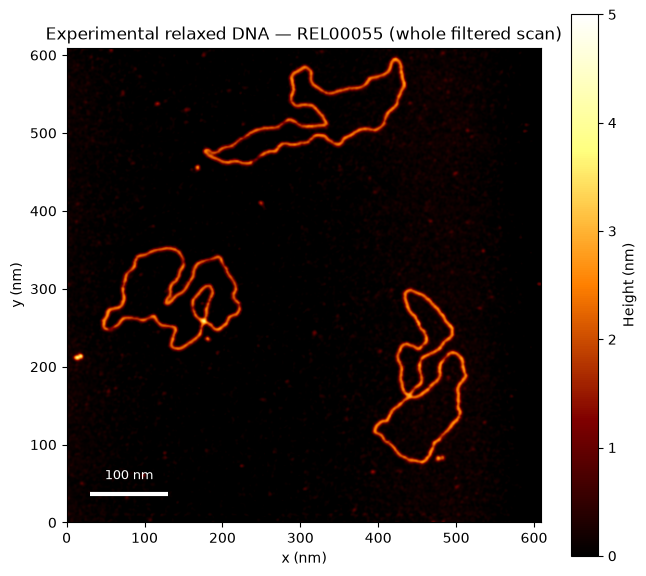

Scan: REL00055 | native nm/pixel: 1.190185546875


In [8]:
real_scan55 = spiral.load_real_frame(REAL_SCAN55_PATH)
spiral.plot_real_frame(real_scan55)
print("Scan:", str(real_scan55["scan_id"]), "| native nm/pixel:", float(real_scan55["nm_per_pixel"]))

## 6. Sanity check — two independently sampled frames

Each frame independently samples its molecule count using the rule from cell 1.2. For `(2, 4)`, each contains 2, 3 or 4 molecules. The count is preserved during generation; molecules are not silently omitted when placement is difficult.

Rows show the two frames. Columns show AFM heights, individual molecule labels in different colours and soft crossing targets. Every panel has a scale bar. Labels list the full projected contour of each molecule; some additional molecules may extend beyond the frame under the selected visibility rule. The title reports both the observed mean count in these two frames and the expected mean of the configured distribution.

Frame seed 55: molecule 1/3, chain seed 1787247953


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


Frame seed 55: molecule 2/3, chain seed 729363554


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


Frame seed 55: molecule 3/3, chain seed 1617533868


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


Frame seed 74: molecule 1/1, chain seed 1920662705


  CUDA unavailable: There is no registered Platform called "CUDA"
Using OpenCL platform.


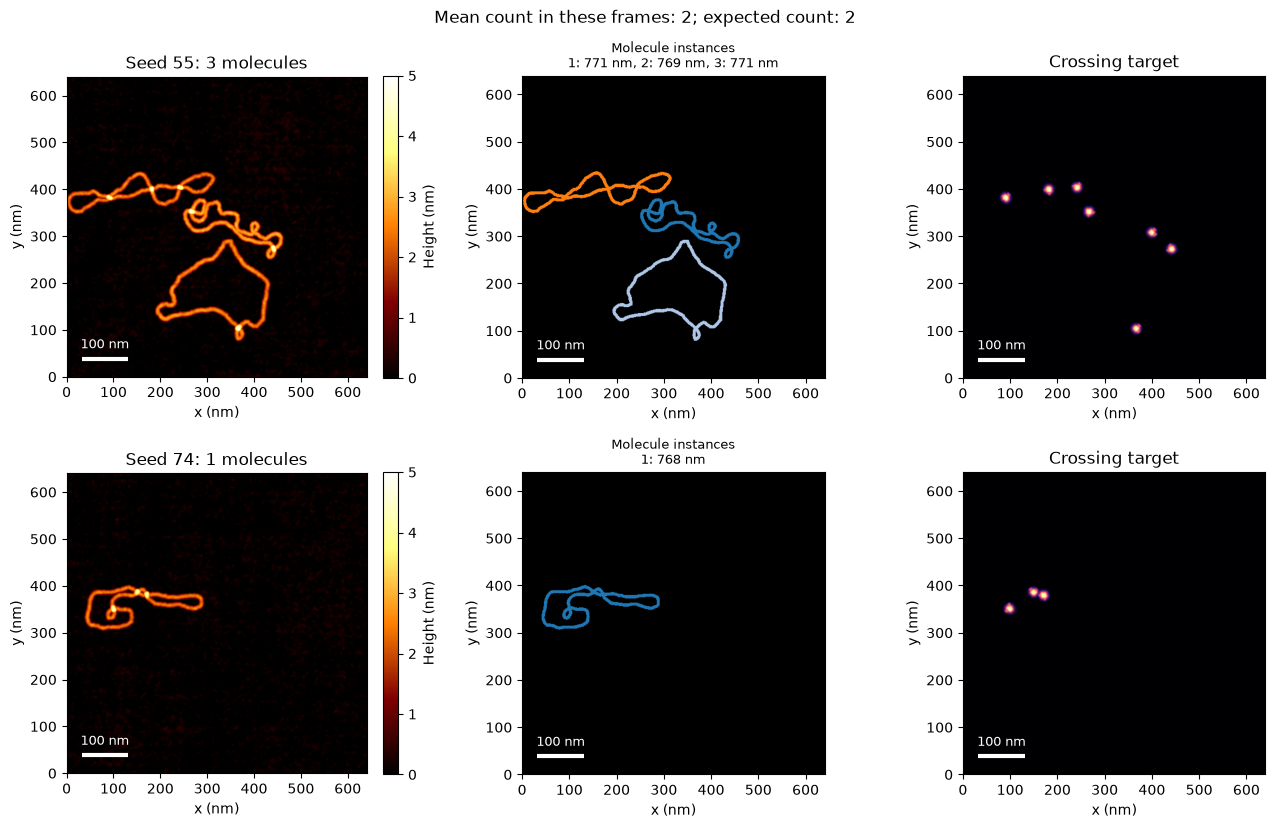

In [9]:
SANITY_SEEDS = [55, 74]
sanity_frames = [
    spiral.generate_frame(seed, FRAME_CONFIG, SIMULATION_SETTINGS, noise_asset,
                          CONTOUR_LENGTHS_NM, DNA_HEIGHTS_NM, TIP_RADII_NM, NOISE_RMS_NM,
                          progress=True)
    for seed in SANITY_SEEDS
]
spiral.plot_frames(sanity_frames, FRAME_CONFIG["mean_molecule_count"]);

## 7. Export a dataset (optional)

Set `GENERATE_DATASET = True` to generate `N_DATASET_FRAMES` new frames. The default 1000 is the requested size of this new export. MD generates each molecule separately, so start with a small number when estimating runtime.

`manifest.csv` records the split, seed, molecule count, physical dimensions and file paths. Each compressed NPZ contains the fine-grid height map, clean image, noise, molecule labels, DNA and crossing masks, the area-averaged model-grid image and masks, and full chain coordinates. JSON files record per-molecule contours, seeds, imaging parameters and visible fractions. Arrays can be loaded with `np.load(..., allow_pickle=False)`.

Splits default to 80/10/10. Molecule seeds are kept distinct across all exported frames and splits. Noise is added once per frame. Existing datasets are protected: choose a new `OUT_DIR` for another run. These exported frames are a new dataset using the shared recipe; the original experiment's cached-scene construction is documented in the README.

In [10]:
GENERATE_DATASET = False
SAVE_PREVIEW_PNGS = False
SPLIT_FRACTIONS = (0.8, 0.1, 0.1)

if GENERATE_DATASET:
    dataset_records = spiral.export_dataset(
        OUT_DIR, N_DATASET_FRAMES, BASE_SEED, FRAME_CONFIG, SIMULATION_SETTINGS, noise_asset,
        CONTOUR_LENGTHS_NM, DNA_HEIGHTS_NM, TIP_RADII_NM, NOISE_RMS_NM,
        split_fractions=SPLIT_FRACTIONS, save_previews=SAVE_PREVIEW_PNGS,
    )
    print("Dataset saved:", OUT_DIR.resolve(), "| frames:", len(dataset_records))
else:
    print("Set GENERATE_DATASET = True to export; the sanity-check frames remain available above.")

Set GENERATE_DATASET = True to export; the sanity-check frames remain available above.


# Part 2. Learn from spiral surveys and plan the second scan

## 8. Imports and settings

Choose `MODEL_KIND = "diffusion"` or `"regression"` (the deterministic U-Net control). **The default loads the original manuscript checkpoint**, with all model and dataset classes in `../spiral_learning_helpers.py`. Set `TRAIN_NEW_MODEL = True` to train using a dataset exported in Part 1. Part 2 can be run independently after Colab setup.

The main experiment used a 12-turn outward spiral with one height sample every 5 nm, a 256 × 256 canvas at 2.5 nm/pixel, and a residual U-Net of base width 64. Diffusion uses 24 sampling steps and 16 **unfiltered** configurations. Its scan-box threshold is fixed at **2/16**; the deterministic probability threshold is **0.05**. Both use zero additional margin, as selected on the 40 simulated validation fields. Thresholds are not fitted to Scan 55 or your uploaded image.

The supplied checkpoints were trained for 30,000 diffusion or 10,000 regression updates. Their selected EMA states are at steps 23,000 and 10,000 respectively. Saved curves describe the original training run. The optional training route uses the same objectives and schedule on your chosen dataset.

In [11]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

HELPER_DIR = Path("..").resolve()
sys.path.insert(0, str(HELPER_DIR))
import spiral_learning_helpers as learn

MODEL_KIND = "diffusion"             # "diffusion" or "regression"
TRAIN_NEW_MODEL = False
USE_CACHED_REFERENCE_PREDICTIONS = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(4)

CHECKPOINT_PATH = HELPER_DIR / "checkpoints" / MODEL_KIND / "manuscript_ema.pt"
HISTORY_PATH = CHECKPOINT_PATH.parent / "training_history.json"
REFERENCE_MANIFEST = HELPER_DIR / "assets/reference-fields/manifest.csv"
TRAIN_DATASET_MANIFEST = Path("spiral_dataset_md/manifest.csv")
TRAINING_OUTPUT_DIR = HELPER_DIR / "checkpoints/user_runs" / MODEL_KIND

MODEL_CONFIG = dict(learn.DIFFUSION_CONFIG)
MODEL_CONFIG["canvas_shape"] = [256, 256]
MODEL_CONFIG["model_nm_per_pixel"] = 2.5
MODEL_CONFIG["batch_size"] = 12
MODEL_CONFIG["seed"] = 260918
TRAINING_UPDATES = 30000 if MODEL_KIND == "diffusion" else 10000
VALIDATE_EVERY = 1000
LOSS_VALIDATION_FIELDS = 64
ROI_VALIDATION_FIELDS = 40

SPIRAL_TURNS = 12
SAMPLE_SPACING_NM = 5.0
MODEL_CONFIG["survey_turns"] = SPIRAL_TURNS
MODEL_CONFIG["sample_spacing_nm"] = SAMPLE_SPACING_NM
DIFFUSION_DRAWS = 16
PREDICTION_SEED = 900001              # original outward_12 inference stream
MODEL_CONFIG["sample_steps"] = 24
OCCUPANCY_THRESHOLD = 2 / 16
REGRESSION_THRESHOLD = 0.05
BOX_MARGIN_NM = 0.0
BOX_SETTINGS = dict(occupancy_threshold=OCCUPANCY_THRESHOLD,
                    regression_threshold=REGRESSION_THRESHOLD, margin_nm=BOX_MARGIN_NM)

PREVIEW_INDEX = 0
REAL_INPUT = "provided_scan55"        # "provided_scan55", "path" or "upload" (Colab)
REAL_FILE_PATH = ""
REAL_FILE_TYPE = "npy"                # "npy" height map in nm, or "spm"
NPY_NM_PER_PIXEL = None               # set your calibration; None assumes the training field extent
SPM_CONFIG_YAML = Path("../../segmentation/configs/topostats_relaxed.yaml")
SPM_CHANNEL = "Height"
SPM_GAUSSIAN_SIZE = None              # None uses the supplied YAML value (1.1 pixels)

print("Selected:", MODEL_KIND, "| device:", DEVICE, "| mode:", "train" if TRAIN_NEW_MODEL else "load manuscript EMA")

Selected: diffusion | device: cpu | mode: load manuscript EMA


## 9. DeepTrack sources and lazy data loading

The manifest stores file paths and split labels. A **DeepTrack Source** holds those records; its lazy pipeline reads an NPZ file, samples the spiral and constructs inputs only when an example is requested. The full dataset is not loaded into RAM. A PyTorch dataset class in the Part 2 helper wraps this pipeline for training.

When loading the manuscript checkpoint, this cell uses the 40 original simulated fields used to select scan-box settings and one held-out simulated preview. Each includes its saved model predictions. For a new training run, set `TRAIN_DATASET_MANIFEST` to the Part 1 export. Training examples use random spiral families, phases and 3–16 turns; validation observations are fixed. Reference masks form targets and assessment metrics, while model inputs contain only measured survey information.

In [12]:
data_manifest = TRAIN_DATASET_MANIFEST if TRAIN_NEW_MODEL else REFERENCE_MANIFEST
validation_records = learn.manifest_records(data_manifest, "validation")
test_records = learn.manifest_records(data_manifest, "test")
validation_data = learn.LazySpiralDataset(validation_records, MODEL_CONFIG, training=False, seed=904)
test_data = learn.LazySpiralDataset(test_records, MODEL_CONFIG, training=False, seed=47000)
train_data = None
if TRAIN_NEW_MODEL:
    training_records = learn.manifest_records(data_manifest, "train")
    train_data = learn.LazySpiralDataset(training_records, MODEL_CONFIG, training=True,
                                        seed=MODEL_CONFIG["seed"])
print("DeepTrack source:", type(validation_data.source).__name__)
print("Validation records:", len(validation_data), "| test records:", len(test_data))
print("Frame arrays are loaded on demand by the helper's lazy pipeline.")

C:\Users\xdutpr\Documents\Codex\2026-09-21\files-mentioned-by-the-user-image\work\colab312_upgrade\venv312\Lib\site-packages\deeptrack\__init__.py:14: UserWarning: TensorFlow is detected in your environment. DeepTrack2 version 2.0++ no longer supports TensorFlow. If you need TensorFlow support, please install the legacy version 1.7 of DeepTrack2:

    pip install deeptrack==1.7

For more details, refer to the DeepTrack documentation.
  warnings.warn(


DeepTrack source: Source
Validation records: 40 | test records: 1
Frame arrays are loaded on demand by the helper's lazy pipeline.


## 10. Training losses and validation metrics

Both models predict height and DNA geometry from the same four condition channels: measured heights, acquisition mask, in-frame flag and an interpolation using measured heights only. Heights are background-subtracted and normalised as $h/2.5-1$. DNA geometry is a signed-distance field (SDF), positive inside DNA and clipped to $[-1,1]$, with a scale of 6.4 nm.

**Deterministic U-Net.** The loss is the sum of mean squared height error on unmeasured in-frame pixels and binary cross-entropy on the DNA-sign logits throughout the frame. It does not optimise Dice directly.

**Diffusion.** EDM denoising reconstructs height and SDF from noisy targets. Height error is evaluated on unmeasured pixels; SDF error is evaluated throughout the frame. The squared error is weighted by

$$w(\sigma)=\frac{\sigma^2+\sigma_{\mathrm{data}}^2}{(\sigma\,\sigma_{\mathrm{data}})^2},\qquad \sigma_{\mathrm{data}}=0.5.$$

Noise levels follow $\log\sigma\sim\mathcal{N}(-1.2,1.2^2)$. At $\sigma<0.5$, the loss also adds **0.05 × soft clDice** for skeleton continuity and **0.02 × relative soft-skeleton length error**. Geometry probabilities for these terms are $\mathrm{sigmoid}(20\,\mathrm{SDF})$. Skeleton precision allows a one-pixel tolerance against the reference mask. Measured heights are pinned during denoising and sampling.

**Validation.** Training curves show the recorded objective and validation loss. The original loss-validation set contained 64 fixed examples; the 40 separate ROI-validation fields selected the scan-box settings. Their settings are kept fixed here. Pixel Dice and IoU use a probability/occupancy threshold of 0.5:

$$\mathrm{Dice}=\frac{2|P\cap T|}{|P|+|T|},\qquad \mathrm{IoU}=\frac{|P\cap T|}{|P\cup T|}.$$

**Scan planning.** Occupancy for scan boxes uses all 16 unfiltered configurations and a threshold of **2/16**, not the 0.5 pixel-metric threshold. Measured DNA anchors are added, each eight-connected region containing an anchor gets a rectangular box, and nested boxes are removed. A reference molecule is covered when at least **95%** of its mask lies inside the box union. Charged saving subtracts the observed survey fraction and the **sum** of second-pass box areas, so overlapping visits are counted. If the boxes exceed one frame, a full second pass replaces them and the survey cost is still charged. These are acquisition-area estimates, not measured scanner-time savings.

## 11. Build or load the chosen architecture

The conditional residual U-Net has four widths (64, 128, 192, 256), two residual blocks per level, GroupNorm, noise-level conditioning and bottleneck self-attention. It outputs two channels: height and DNA SDF/logits. Both choices use the same network architecture. Regression supplies a zero state and zero noise embedding; diffusion uses EDM preconditioning and iterative denoising. This cell prints the selected architecture and parameter count.

In [13]:
if TRAIN_NEW_MODEL:
    torch.manual_seed(MODEL_CONFIG["seed"])
    model = learn.ConditionalUNet(MODEL_CONFIG).to(DEVICE)
    checkpoint = None
else:
    sampling_settings = {key: MODEL_CONFIG[key] for key in (
        "sample_steps", "sigma_min", "sigma_max", "rho", "sigma_data",
        "survey_turns", "sample_spacing_nm",
    )}
    model, loaded_config, checkpoint = learn.load_checkpoint(CHECKPOINT_PATH, MODEL_KIND, DEVICE)
    MODEL_CONFIG.update(loaded_config)
    MODEL_CONFIG.update(sampling_settings)
learn.describe_model(model, MODEL_CONFIG, MODEL_KIND, checkpoint)

Architecture: conditional EDM diffusion
Parameters: 11,965,058
Canvas: [256, 256] | model nm/pixel: 2.5
Manuscript EMA checkpoint step: 23000
ConditionalUNet(
  (time): TimeEmbedding(
    (mlp): Sequential(
      (0): Linear(in_features=128, out_features=256, bias=True)
      (1): SiLU()
      (2): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (stem): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down): ModuleList(
    (0): ModuleList(
      (0-1): 2 x ResidualBlock(
        (norm1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (norm2): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (time): Linear(in_features=128, out_features=128, bias=True)
        (skip): Identity()
      )
    )
    (1): ModuleList(
      (0-1): 2 x ResidualBlock(
        (norm1): Gro

## 12. Training and validation, or load the saved run

By default, this cell reads the original training history and retains the loaded manuscript EMA model. To train, enable `TRAIN_NEW_MODEL` in cell 8 and rerun Part 2. Supply a manifest containing train, validation and test splits.

Training uses AdamW at 2 × 10⁻⁴, weight decay 10⁻⁴, 1000 warm-up updates and cosine decay to 10% of the initial learning rate. Batch size is 12, gradient norm is clipped at 1, and the EMA decay approaches 0.999. The lowest validation-loss EMA checkpoint is saved in a separate user-run directory. The supplied checkpoints are preserved.

In [14]:
if TRAIN_NEW_MODEL:
    model, history, checkpoint = learn.train_model(
        model, train_data, validation_data, MODEL_CONFIG, MODEL_KIND, TRAINING_OUTPUT_DIR,
        updates=TRAINING_UPDATES, validation_every=VALIDATE_EVERY,
        validation_fields=LOSS_VALIDATION_FIELDS,
    )
else:
    history = json.loads(HISTORY_PATH.read_text(encoding="utf-8"))
    print("Loaded original training history; selected EMA step:", checkpoint["step"])

Loaded original training history; selected EMA step: 23000


## 13. Validation metrics and curves

The curves describe the selected training run. The table assesses the separate ROI-validation fields using the fixed manuscript thresholds. Matching reference caches reproduce the saved experiment predictions; disabling `USE_CACHED_REFERENCE_PREDICTIONS` runs the selected network again. New checkpoints and new observations use live inference automatically. Dice/IoU assess the mask at 0.5; coverage and area savings assess the planned boxes at the lower scan-planning threshold.

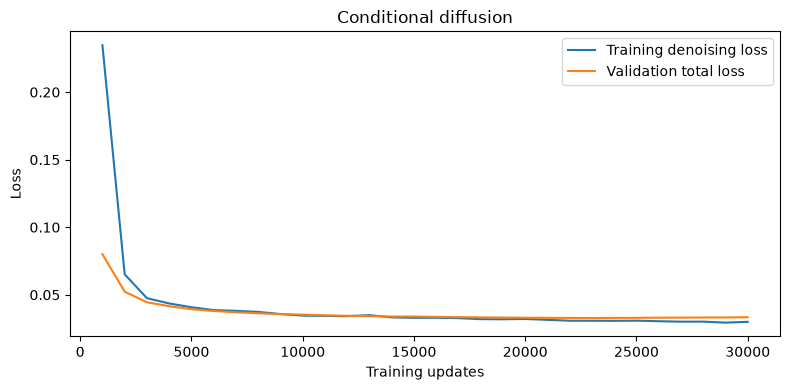

,frame,boxes,survey_fraction,second_pass_fraction,frame_saved,reference_molecules,molecules_scanned,minimum_coverage,full_frame_fallback,dice,iou
0,validation_000,2,0.059441,0.350429,0.590130,2,2,0.992267,False,0.887705,0.798084
1,validation_001,1,0.075584,0.467561,0.456856,1,1,1.000000,False,0.915867,0.844792
2,validation_002,1,0.071886,0.306714,0.621400,1,1,1.000000,False,0.908985,0.833155
3,validation_003,3,0.065094,0.423730,0.511176,3,2,0.850966,False,0.797329,0.662965
4,validation_004,3,0.076687,0.633994,0.289318,3,3,1.000000,False,0.851630,0.741599
5,validation_005,3,0.064258,0.534141,0.401602,3,3,1.000000,False,0.733394,0.579023
6,validation_006,1,0.077280,0.430437,0.492283,1,1,1.000000,False,0.914930,0.843198
7,validation_007,2,0.063886,0.568149,0.367964,2,2,1.000000,False,0.826805,0.704747
8,validation_008,2,0.073418,0.575816,0.350765,2,2,0.999367,False,0.879244,0.784509
9,validation_009,2,0.057160,0.353611,0.589228,2,2,1.000000,False,0.870457,0.770628


Molecules covered at ≥95%: 73/76
Mean charged frame saving: 50.4%


In [15]:
learn.plot_history(history, MODEL_KIND)
validation_metrics = learn.evaluate_dataset(
    model, validation_data, MODEL_CONFIG, MODEL_KIND, checkpoint,
    use_cached=USE_CACHED_REFERENCE_PREDICTIONS, samples=DIFFUSION_DRAWS,
    limit=ROI_VALIDATION_FIELDS, **BOX_SETTINGS,
    prediction_seed=PREDICTION_SEED,
)
validation_table = learn.show_metrics(validation_metrics)

## 14. Prediction preview on a reference simulated scan

This cell uses a held-out simulated field. It displays measured spiral pixels, ensemble occupancy or deterministic probability, the resulting second-pass boxes and, for diffusion, four of the sixteen generated configurations. The reference height and labels are used for display and assessment, never for choosing the boxes. The main rule uses every draw without the topology/connectivity filter used in the separate augmentation experiment.

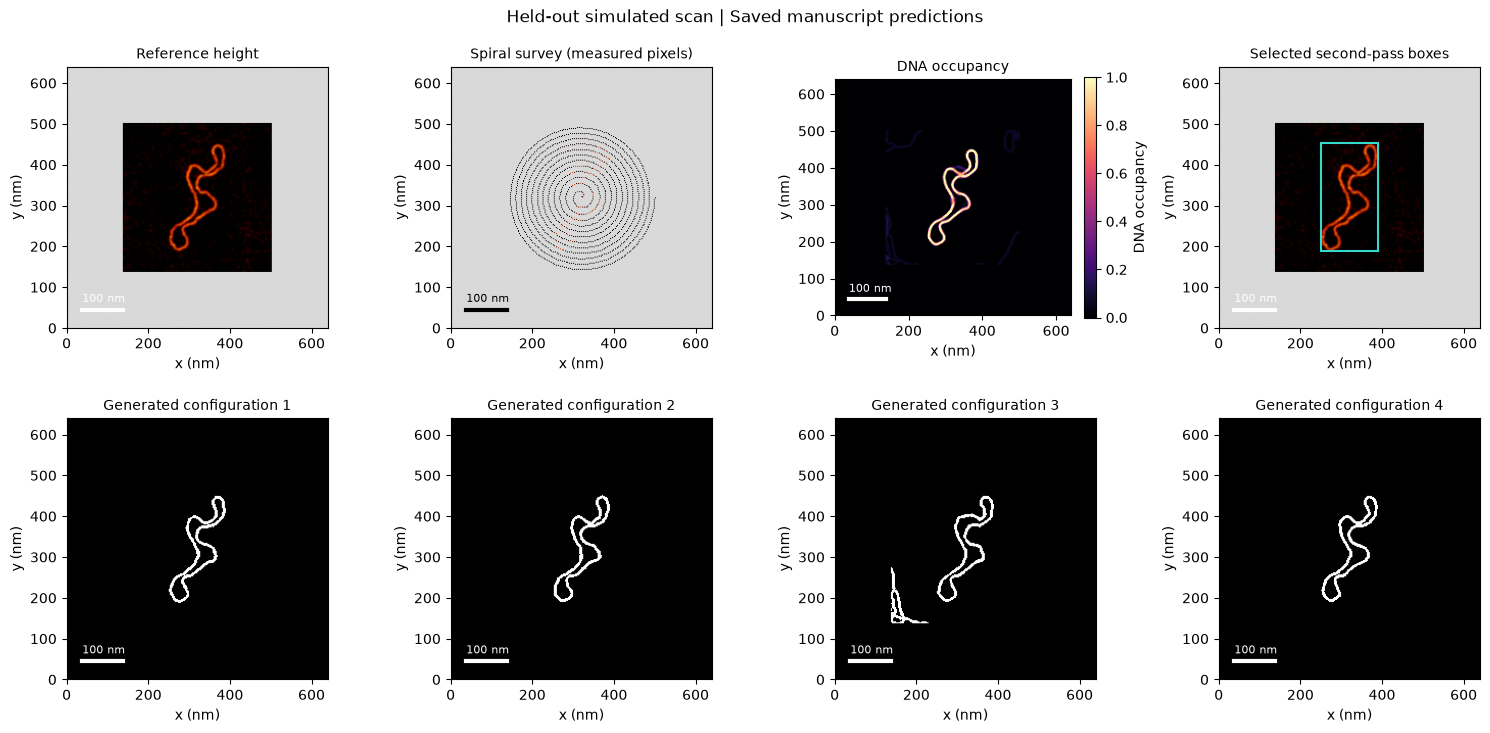

,frame,boxes,survey_fraction,second_pass_fraction,frame_saved,reference_molecules,molecules_scanned,minimum_coverage,full_frame_fallback,dice,iou
0,test_000,1,0.070417,0.278476,0.651107,1,1,1.0,False,0.910011,0.834881


Molecules covered at ≥95%: 1/1
Mean charged frame saving: 65.1%


In [16]:
preview_case = test_data.case(PREVIEW_INDEX)
preview_prediction = learn.predict_case(
    model, preview_case, MODEL_CONFIG, MODEL_KIND, checkpoint,
    use_cached=USE_CACHED_REFERENCE_PREDICTIONS, samples=DIFFUSION_DRAWS,
    seed=PREDICTION_SEED,
)
preview_plan = learn.scan_boxes(preview_prediction, preview_case, **BOX_SETTINGS)
learn.plot_prediction(preview_case, preview_prediction, preview_plan, "Held-out simulated scan")
preview_metrics = learn.show_metrics([
    learn.assess_plan(preview_case, preview_plan, preview_prediction["probability"])
])

## 15. Real data — Scan 55 or your own SPM/NPY file

The default uses the whole filtered relaxed-DNA **Scan 55** from `../../common-assets/example-frames/`. As in the experiment, it is resampled at physical pixel centres and centred within the 640-nm canvas with an in-frame flag. Its automatic reference proposals allow molecular coverage to be assessed.

To analyse your own file, set `REAL_INPUT = "path"` and supply `REAL_FILE_PATH`, or select `"upload"` on Colab. Choose `REAL_FILE_TYPE = "spm"` or `"npy"`. NPY heights must be in nm; supply `NPY_NM_PER_PIXEL` when known. SPM heights are loaded with their native calibration and filtered using TopoStats and the selected YAML; channel and Gaussian size are exposed in cell 8.

Uploaded images are checked against the training frame. A mismatch triggers a warning that the image is resized and performance may be sub-optimal. The original physical extent is retained, and the printed boxes are mapped back to source coordinates. A missing NPY calibration assumes the training field extent and is reported. Custom files use live inference. Without independent reference masks, pixel Dice/IoU and molecular coverage are left unscored; the scan plan still reports box count and charged area.

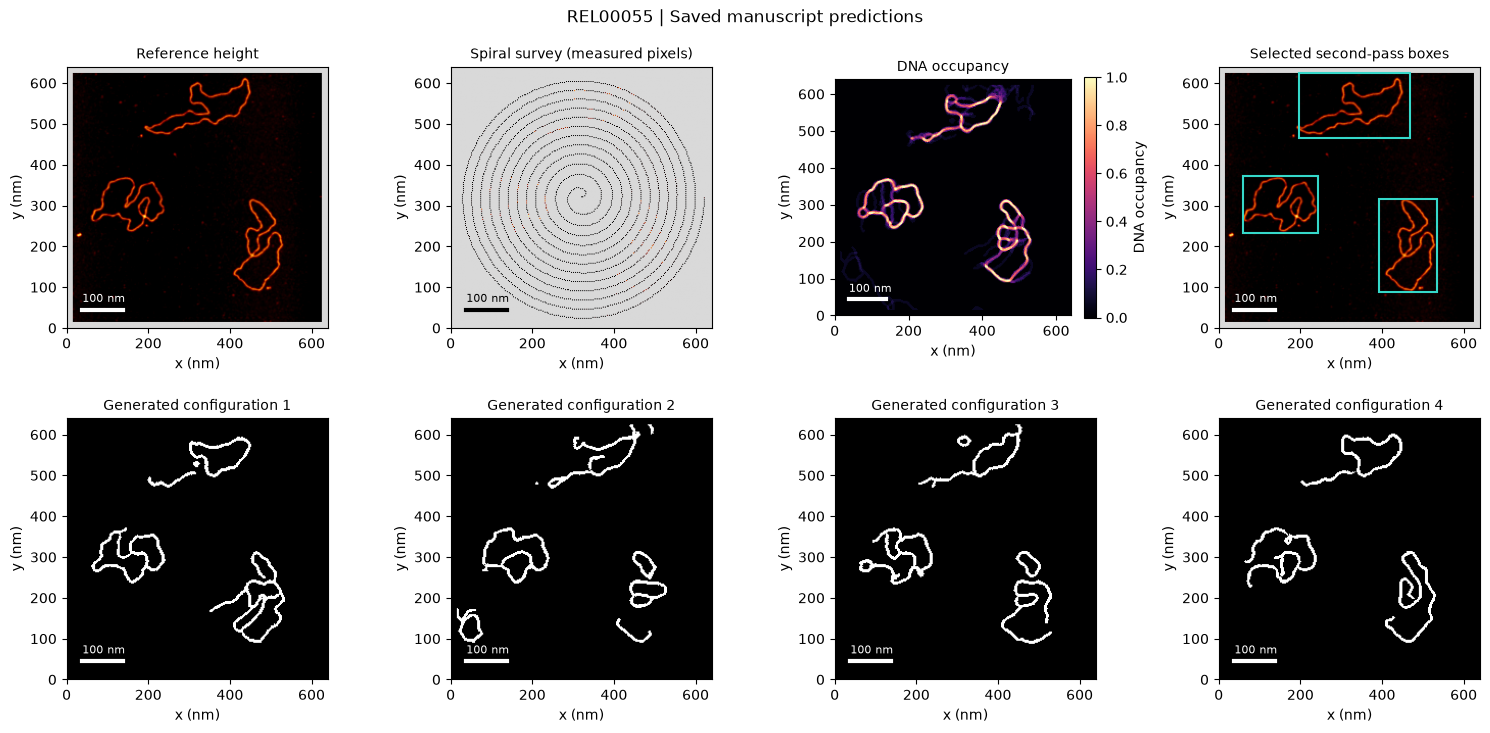

,frame,boxes,survey_fraction,second_pass_fraction,frame_saved,reference_molecules,molecules_scanned,minimum_coverage,full_frame_fallback,dice,iou
0,REL00055,3,0.042193,0.271886,0.685921,3,3,0.985011,False,0.638684,0.469166


Molecules covered at ≥95%: 3/3
Mean charged frame saving: 68.6%
Scan boxes in source coordinates (x0, y0, x1, y1), nm:
[(182.1875, 449.6875, 452.1875, 609.375), (377.1875, 72.1875, 519.6875, 299.6875), (44.6875, 217.1875, 227.1875, 357.1875)]


In [17]:
if REAL_INPUT == "provided_scan55":
    real_field = learn.bundled_scan55(
        Path("../../common-assets/example-frames/relaxed_scan55.npz"),
        HELPER_DIR / "assets/scan55_predictions.npz",
    )
else:
    selected_path = learn.upload_real_file() if REAL_INPUT == "upload" else Path(REAL_FILE_PATH)
    real_field = learn.user_field(
        selected_path, MODEL_CONFIG, REAL_FILE_TYPE, NPY_NM_PER_PIXEL,
        SPM_CONFIG_YAML, SPM_CHANNEL, SPM_GAUSSIAN_SIZE,
    )
real_case = learn.prepare_case(real_field, MODEL_CONFIG, turns=SPIRAL_TURNS,
                              sample_spacing_nm=SAMPLE_SPACING_NM)
real_prediction = learn.predict_case(
    model, real_case, MODEL_CONFIG, MODEL_KIND, checkpoint,
    use_cached=USE_CACHED_REFERENCE_PREDICTIONS, samples=DIFFUSION_DRAWS,
    seed=PREDICTION_SEED,
)
real_plan = learn.scan_boxes(real_prediction, real_case, **BOX_SETTINGS)
learn.plot_prediction(real_case, real_prediction, real_plan, real_field["name"])
real_metrics = learn.show_metrics([
    learn.assess_plan(real_case, real_plan, real_prediction["probability"])
])
print("Scan boxes in source coordinates (x0, y0, x1, y1), nm:")
print(learn.source_boxes_nm(real_field, real_case, real_plan))

## Further resources and citation

For advanced biomolecular tracing and topology analysis, visit [TopoStats](https://github.com/AFM-SPM/TopoStats). For other simulation and deep-learning workflows in microscopy, visit [DeepTrackAI](https://github.com/DeepTrackAI).

[Prakhar Dutta](https://www.spiedigitallibrary.org/profile/notfound?author=Prakhar_Dutta), [Jiacheng Huang](https://www.spiedigitallibrary.org/profile/notfound?author=Jiacheng_Huang), [Nazli Demirpehlivan](https://www.spiedigitallibrary.org/profile/notfound?author=Nazli_Demirpehlivan), et al. "ASAP (AFM simulation and analysis pipeline): a unified deep learning framework for simulation, quality control, and segmentation in atomic force microscopy", Proc. SPIE 14198, Emerging Topics in Artificial Intelligence (ETAI) 2026, 1419804 (9 Oct 2026); [https://doi.org/10.1117/12.3113626](https://doi.org/10.1117/12.3113626)